<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · How much of a county is water?

A county's total area can conceal a very different land footprint. Which Massachusetts counties have a large water share, and how sensitive is that shortlist to the cutoff we choose?

We will read a **bounded live public layer** from Census TIGERweb through the real ArcGIS VGI worker, check the returned population against a separate server count, and compare land area, water share and two ways of averaging counties. Python supplies presentation; visible SQL performs the retrieval and analysis. There are no synthetic or fallback records.

## Choose the comparison

The geography is fixed to Massachusetts, state FIPS **25**. `WATER_SHARE_THRESHOLD` is an inclusive fraction of total county area, between 0 and 1. It is an exploratory cutoff, not an official Census classification. Restart the kernel and run all after editing.

The source is a **current boundary layer**, not an observation time series. Its live metadata description and retrieval interval are shown below. Rerunning fetches the source again; a change between runs can reflect a source update as well as a parameter change.

In [1]:
WATER_SHARE_THRESHOLD = 0.25  # Fraction, 0–1 inclusive; final experiment: 0.50

In [2]:
from tempfile import TemporaryDirectory
import hashlib
import json
import os
from datetime import datetime, timezone
from urllib.request import urlopen

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(WATER_SHARE_THRESHOLD, (int, float)) and not isinstance(WATER_SHARE_THRESHOLD, bool)
assert 0 <= WATER_SHARE_THRESHOLD <= 1
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
# Prevent a test harness's endpoint overrides from silently changing public provenance.
for name in ("ARCGIS_HUB_API", "ARCGIS_PORTAL_API"):
    os.environ.pop(name, None)
LAYER_URL = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/1"
started_utc = datetime.now(timezone.utc)
with urlopen(LAYER_URL + "?f=pjson", timeout=45) as response:
    layer_metadata = json.load(response)
if "error" in layer_metadata:
    raise RuntimeError(layer_metadata["error"])
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False})
LAND, WATER, SELECTED = "#b78a4b", "#217da6", "#a84234"
def prose(text):
    display(Markdown(text))
def finish(fig):
    fig.text(0.01, 0.01, f"Source: U.S. Census Bureau TIGERweb · MA counties · retrieved {started_utc:%Y-%m-%d %H:%M UTC}", fontsize=8, color="#555555")
    fig.tight_layout(rect=(0, 0.045, 1, 0.97))
    plt.show()
fixture_secret_directory = TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == [], "Notebook must start without SQL secrets"
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-arcgis/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-arcgis/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-arcgis/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-arcgis/notebooks/pyproject.toml.

## Connect to a pinned release

The literal release location below downloads and caches the published worker for the current platform. It does not use this checkout's source or binaries. We attach without a directory URL so discovery does not enumerate unrelated services.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'arcgis' AS arcgis (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-arcgis@v0.6.0'
);

,Success


## Establish the population, then keep one local snapshot

The count function's **named `where_clause`** restricts the server request. The feature query uses a direct equality predicate on `STATE`, which this worker pushes to ArcGIS; it then checks rows locally. We request only identifiers and area attributes, so no county polygons are downloaded. There is no `LIMIT`: all matching counties are needed for valid denominators.

These two requests are separate observations of a live source. Matching counts and unique identifiers are useful checks, but cannot prove the service stayed unchanged between requests.

In [4]:
%%sql
CREATE TABLE server_count AS
SELECT feature_count
FROM arcgis.main.arcgis_count(
    'https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/1',
    where_clause := 'STATE = ''25'''
);

CREATE TABLE county_snapshot AS
SELECT GEOID AS geoid, STATE AS state_fips, NAME AS county,
       AREALAND AS land_m2, AREAWATER AS water_m2
FROM arcgis.main.arcgis_query(
    'https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/1'
)
WHERE STATE = '25';

,Count


In [5]:
%%sql availability <<
SELECT (SELECT feature_count FROM server_count) AS reported_count,
       count(*) AS downloaded_count,
       count(DISTINCT geoid) AS distinct_count,
       count(*) FILTER (WHERE land_m2 IS NULL OR water_m2 IS NULL) AS missing_area,
       count(*) FILTER (WHERE land_m2 < 0 OR water_m2 < 0
                        OR land_m2 + water_m2 <= 0) AS invalid_area,
       count(*) FILTER (WHERE state_fips <> '25') AS wrong_state
FROM county_snapshot;

In [6]:
finished_utc = datetime.now(timezone.utc)
display(availability)
a = availability.iloc[0]
assert a.reported_count == a.downloaded_count == a.distinct_count and a.downloaded_count > 0
assert a.missing_area == a.invalid_area == a.wrong_state == 0
snapshot = con.execute("SELECT * FROM county_snapshot ORDER BY geoid").fetchdf()
fingerprint = hashlib.sha256(snapshot.to_csv(index=False, lineterminator="\n").encode()).hexdigest()
prose(f"**Availability passed:** {int(a.downloaded_count)} unique counties, matching the server count; "
      "no missing or invalid area values. Missing values would stop this example, rather than become zeros. "
      f"Retrieval: **{started_utc:%Y-%m-%d %H:%M:%S UTC}–{finished_utc:%H:%M:%S UTC}**. "
      f"Live layer description: **{layer_metadata.get('description', 'not supplied')}**. "
      f"Sorted attribute snapshot SHA-256: `{fingerprint}`. "
      "All remaining queries use the materialized in-memory snapshot.")

,reported_count,downloaded_count,distinct_count,missing_area,invalid_area,wrong_state
0,14,14,14,0,0,0


**Availability passed:** 14 unique counties, matching the server count; no missing or invalid area values. Missing values would stop this example, rather than become zeros. Retrieval: **2026-11-14 11:04:40 UTC–11:04:44 UTC**. Live layer description: **Counties (or statistically equivalent entities); January 1, 2026 vintage**. Sorted attribute snapshot SHA-256: `6923fb5740f693f00cb4253139dad855c845498b6bfa3c46befead70b796ec36`. All remaining queries use the materialized in-memory snapshot.

## Separate area from share

The [Census area definitions](https://www2.census.gov/geo/pdfs/reference/GARM/Ch15GARM.pdf) distinguish land and water; the TIGER area fields use square metres. Divide by 1,000,000 for square kilometres. We use the source's area attributes, avoiding an area calculation on longitude/latitude geometry.

For each county, water share is `water / (land + water)`. The **unweighted mean** gives every county one vote. The **area-weighted share** divides all county water area by all county total area; it answers a different question. Water boundaries and Census classification conventions matter: this is neither a water-quality measure nor a flood-risk estimate.

In [7]:
%%sql
CREATE TABLE county_areas AS
SELECT geoid, county,
       land_m2 / 1000000.0 AS land_km2,
       water_m2 / 1000000.0 AS water_km2,
       (land_m2 + water_m2) / 1000000.0 AS total_km2,
       water_m2::DOUBLE / (land_m2 + water_m2) AS water_share
FROM county_snapshot;

CREATE TABLE ranked_counties AS
SELECT *,
       dense_rank() OVER (ORDER BY total_km2 DESC) AS total_area_rank,
       dense_rank() OVER (ORDER BY land_km2 DESC) AS land_area_rank,
       water_share >= {{WATER_SHARE_THRESHOLD}} AS meets_cutoff
FROM county_areas;

,Count


In [8]:
%%sql counties <<
SELECT county, land_km2, water_km2, total_km2, water_share,
       total_area_rank, land_area_rank, meets_cutoff
FROM ranked_counties
ORDER BY water_share DESC, county;

In [9]:
display(counties.round({"land_km2": 1, "water_km2": 1, "total_km2": 1, "water_share": 4}))

,county,land_km2,water_km2,total_km2,water_share,total_area_rank,land_area_rank,meets_cutoff
0,Nantucket County,119.6,666.8,786.5,0.8479,13,14,True
1,Dukes County,267.3,1004.3,1271.6,0.7898,11,12,True
2,Barnstable County,1020.9,2360.4,3381.3,0.6981,2,11,True
3,Suffolk County,150.9,160.5,311.4,0.5154,14,13,True
4,Essex County,1275.6,870.2,2145.8,0.4055,6,9,True
5,Plymouth County,1705.6,1126.1,2831.6,0.3977,3,5,True
6,Bristol County,1432.6,357.4,1790.0,0.1997,8,7,False
7,Norfolk County,1025.9,124.9,1150.9,0.1086,12,10,False
8,Worcester County,3912.6,177.4,4090.0,0.0434,1,1,False
9,Franklin County,1810.9,65.6,1876.5,0.0350,7,4,False


In [10]:
%%sql summary <<
SELECT count(*) AS county_count,
       sum(land_km2) AS land_km2, sum(water_km2) AS water_km2,
       avg(water_share) AS mean_county_share,
       sum(water_km2) / sum(total_km2) AS area_weighted_share,
       count(*) FILTER (WHERE meets_cutoff) AS selected_count,
       sum(total_km2) FILTER (WHERE meets_cutoff) / sum(total_km2) AS selected_area_share
FROM ranked_counties;

In [11]:
display(summary.round(4))
s = summary.iloc[0]
water_leader = counties.iloc[0]
land_leader = counties.sort_values("land_km2", ascending=False).iloc[0]
prose(f"**{water_leader.county} has the largest water share ({water_leader.water_share:.1%}); "
      f"{land_leader.county} has the largest land area ({land_leader.land_km2:,.0f} km²).** "
      f"Across counties, the unweighted mean water share is **{s.mean_county_share:.1%}**, "
      f"while the area-weighted share is **{s.area_weighted_share:.1%}**. "
      "The difference comes from giving differently sized counties different weights, not from missing records.")

,county_count,land_km2,water_km2,mean_county_share,area_weighted_share,selected_count,selected_area_share
0,14,20204.4951,7130.5555,0.2969,0.2609,6,0.3925


**Nantucket County has the largest water share (84.8%); Worcester County has the largest land area (3,913 km²).** Across counties, the unweighted mean water share is **29.7%**, while the area-weighted share is **26.1%**. The difference comes from giving differently sized counties different weights, not from missing records.

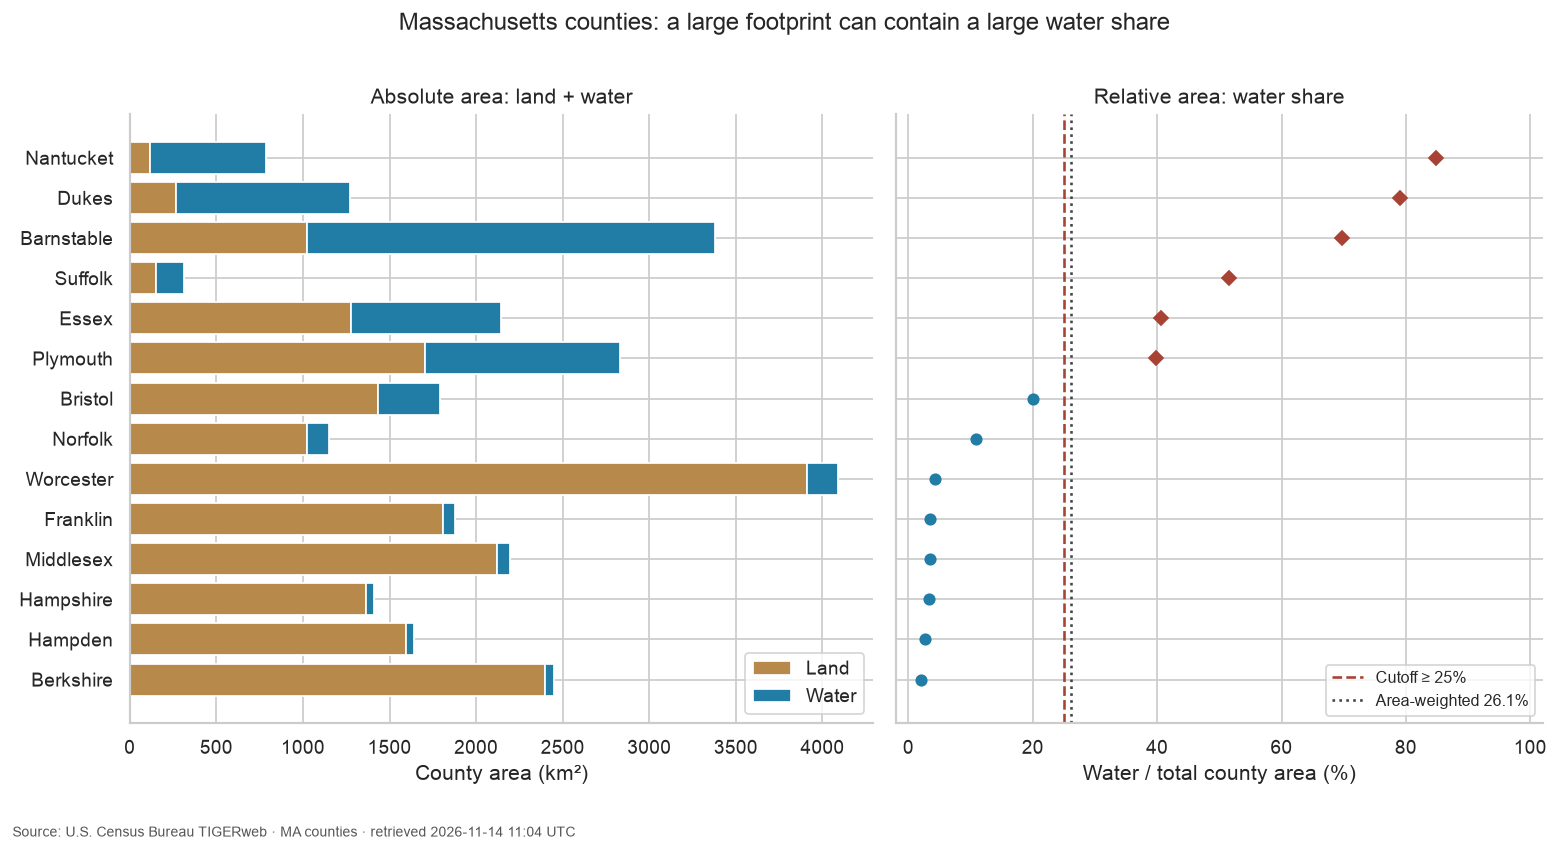

In [12]:
plot = counties.sort_values("water_share")
y = np.arange(len(plot))
fig, axes = plt.subplots(1, 2, figsize=(12.6, 6.8), sharey=True, gridspec_kw={"width_ratios": [1.15, 1]})
axes[0].barh(y, plot.land_km2, color=LAND, label="Land")
axes[0].barh(y, plot.water_km2, left=plot.land_km2, color=WATER, label="Water")
axes[0].set_yticks(y, plot.county.str.replace(" County", "", regex=False))
axes[0].set_xlabel("County area (km²)")
axes[0].set_title("Absolute area: land + water")
axes[0].legend(loc="lower right")
for idx, (_, row) in enumerate(plot.iterrows()):
    axes[1].plot(row.water_share * 100, idx, "D" if row.meets_cutoff else "o",
                 color=SELECTED if row.meets_cutoff else WATER, markersize=6)
axes[1].axvline(WATER_SHARE_THRESHOLD * 100, color=SELECTED, linestyle="--", label=f"Cutoff ≥ {WATER_SHARE_THRESHOLD:.0%}")
axes[1].axvline(s.area_weighted_share * 100, color="#444444", linestyle=":", label=f"Area-weighted {s.area_weighted_share:.1%}")
axes[1].set(xlabel="Water / total county area (%)", xlim=(-2, 102), title="Relative area: water share")
axes[1].legend(loc="lower right", fontsize=9)
fig.suptitle("Massachusetts counties: a large footprint can contain a large water share", fontsize=14)
finish(fig)

The same county order appears in both panels. Bar lengths show absolute area; points show a percentage with a fixed 0–100% scale. Diamond markers meet the chosen cutoff. Offshore and inland water remain part of the source's county-area accounting; these charts do not identify where people live or where development is possible.

## How sensitive is the shortlist?

Reclassifying the same snapshot isolates the effect of a cutoff. The next SQL evaluates thresholds from 0% to 100%, plus the exact selected value, without querying ArcGIS again. Raising an inclusive threshold cannot add counties. The curve is a step function because the population is finite.

In [13]:
%%sql sensitivity <<
WITH cutoffs AS (
    SELECT i / 100.0 AS cutoff FROM range(0, 101) t(i)
    UNION SELECT {{WATER_SHARE_THRESHOLD}}::DOUBLE
), exact_breaks AS (
    SELECT cutoff FROM cutoffs
    UNION SELECT water_share AS cutoff FROM county_areas
)
SELECT cutoff,
       count(*) FILTER (WHERE water_share >= cutoff) AS selected_count
FROM exact_breaks CROSS JOIN county_areas
GROUP BY cutoff
ORDER BY cutoff;

At **≥25% water**, the shortlist contains **6 of 14 counties** and **39.2% of total county area**. Selected counties: Nantucket County, Dukes County, Barnstable County, Suffolk County, Essex County, Plymouth County. This is a description of geography under a chosen rule; no policy or hazard classification follows from it.

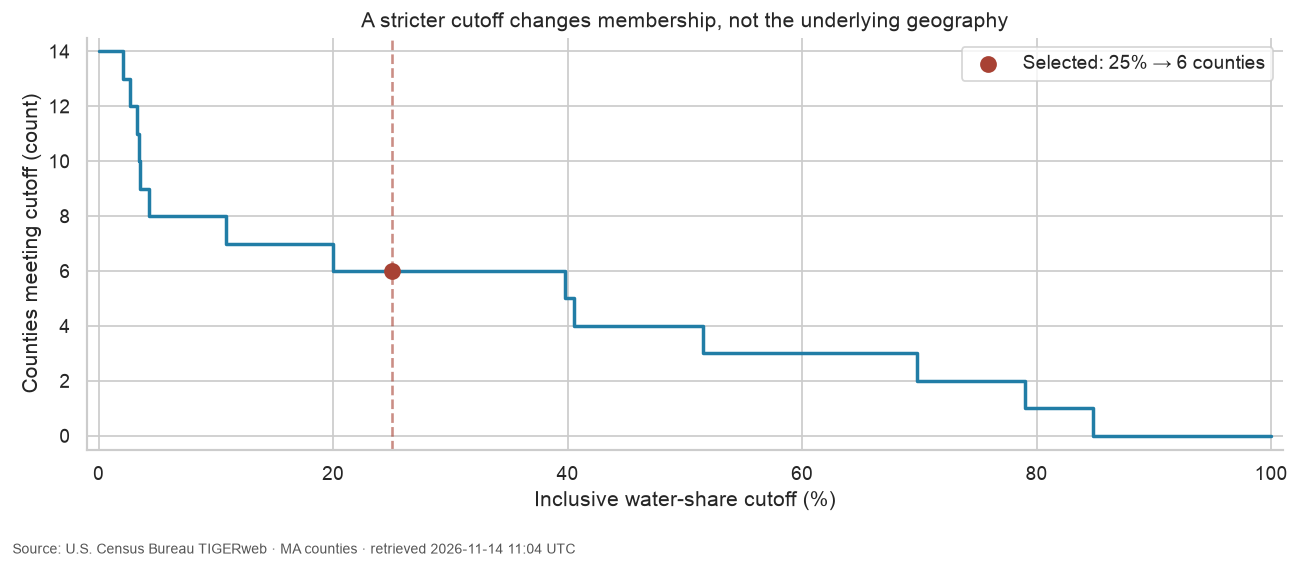

In [14]:
selected = counties[counties.meets_cutoff]
selected_area_share = 0 if pd.isna(s.selected_area_share) else s.selected_area_share
prose(f"At **≥{WATER_SHARE_THRESHOLD:.0%} water**, the shortlist contains **{int(s.selected_count)} "
      f"of {int(s.county_count)} counties** and **{selected_area_share:.1%} of total county area**. "
      + ("Selected counties: " + ", ".join(selected.county) + ". " if len(selected) else "No county meets this cutoff. ")
      + "This is a description of geography under a chosen rule; no policy or hazard classification follows from it.")
assert (sensitivity.selected_count.diff().dropna() <= 0).all()
fig, ax = plt.subplots(figsize=(10.5, 4.7))
# At a county's exact share it remains selected; immediately above it it drops.
ax.step(sensitivity.cutoff * 100, sensitivity.selected_count, where="pre", color=WATER, linewidth=2)
ax.scatter([WATER_SHARE_THRESHOLD * 100], [s.selected_count], color=SELECTED, s=75, zorder=3,
           label=f"Selected: {WATER_SHARE_THRESHOLD:.0%} → {int(s.selected_count)} counties")
ax.axvline(WATER_SHARE_THRESHOLD * 100, color=SELECTED, linestyle="--", alpha=.6)
ax.set(xlabel="Inclusive water-share cutoff (%)", ylabel="Counties meeting cutoff (count)",
       xlim=(-1, 101), ylim=(-.5, len(counties)+.5), title="A stricter cutoff changes membership, not the underlying geography")
ax.set_yticks(range(0, len(counties)+1, 2))
ax.legend(loc="upper right")
finish(fig)

## One change to test

Change only **`WATER_SHARE_THRESHOLD` from `0.25` to `0.50`**, then restart and run all into a separate experiment copy. Predict fewer or the same selected counties. Compare the shortlist count, names and selected area share; the absolute land/water bars and the two overall averages should stay unchanged **if the source snapshot hash matches**.

A live rerun can return revised data. Check the SHA-256 before attributing every difference to the cutoff. The saved experiment verifies this comparison at execution time, not a permanent promise about a changing service. Reset to **`0.25`** afterward. The [README](README.md) gives the exact separate-output command and explains the release pin.

The example demonstrates bounded attribute retrieval, reconciliation, weighting and classification sensitivity. It does not estimate coastal exposure, available land, population density or future water levels.

In [15]:
con.close()
fixture_secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and reruns](README.md)